# Decision Trees and Ensemble Learning

Welcome to the laboratory for dicision tress and tree-based ensemble algorithms.

## 6.1 Credit Risk Scoring Project

Dataset: https://github.com/gastonstat/CreditScoring

    

In [1]:
# Environment setup

import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

# Data source

# data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv'
data = "CreditScoring.csv"

In [2]:
# Load Data into environment

!wget $data

--2026-11-01 11:55:08--  http://creditscoring.csv/
Resolving creditscoring.csv (creditscoring.csv)... failed: Name or service not known.
wget: unable to resolve host address ‘creditscoring.csv’


In [3]:
df = pd.read_csv(data)
df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [4]:
# Prepare the data for ML processing

df.columns = df.columns.str.lower()

### Re-encoding the categorical variables

The columns `status`, `home`, `marital`, `records` and job are categorical, but in the file they are encoded as numbers. For example, status is 1, 2 or 0. That's not very intuitive, so we decode them into strings.

In [5]:
df.status.value_counts()

status
1    3200
2    1254
0       1
Name: count, dtype: int64

1 = paid back the loan
2 = defaulted

We will use pd.map() to first translate the numbers into strings()

In [6]:
status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}

df.status = df.status.map(status_values)

Usw.

In [7]:
home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

In [8]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


### Missing Values

"Not every problem shows up as a missing value. Let's look at the summary statistics:"

In [9]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


The maximum values of `income`, `assets` and `debt` look suspicious: 99999999. This dataset encodes missing values as a long number of nines. Instead of NaN, "unknown" became 99999999. We replace these values with NaN:

In [10]:
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

In [11]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


### Removing the One Record with a Status of Unknown

We also have that single customer with status unk. Since we only care about the two classes - ok and default - we remove this row:

In [12]:
# Make a new dataframe from the old dataframe using every record, so long as the status is not 'unk'. 
# Then reset the dataframe index

df = df[df.status != 'unk'].reset_index(drop=True)

In [13]:
df.count()

status       4454
seniority    4454
home         4454
time         4454
age          4454
marital      4454
records      4454
job          4454
expenses     4454
income       4420
assets       4407
debt         4436
amount       4454
price        4454
dtype: int64

### Split source data in to Train / Validation / Test

Now we split the data. As in the previous modules, we do it in two steps: first we split off the test set (20%), then we split the rest into train and validation (75/25 of what remains, which gives us the 60/20/20 distribution):

In [14]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

In [15]:
# We reset the indexes so they are fresh and unique in each dataframe:

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

### Preparing the Target Variable

The models give us a probability, so the target needs to be a number. We encode `status`: 0 for `ok`, 1 for `default`:

In [16]:
y_train = (df_train.status == 'default').astype('int').values
y_val = (df_val.status == 'default').astype('int').values
y_test = (df_test.status == 'default').astype('int').values

Finally, we delete status from the dataframes - otherwise we would use the target as a feature, and the model would learn to cheat:

In [17]:
del df_train['status']
del df_val['status']
del df_test['status']

## Decision Trees

We train our first decision tree with scikit-learn on the credit scoring data, see what overfitting looks like, and learn how to control the size of a tree. The following function is an algorithm that _could_ be used to perform credit scoring.

In [18]:
def assess_risk(client):
    if client['records'] == 'yes':
        if client['job'] == 'parttime':
            return 'default'
        else:
            return 'ok'
    else:
        if client['assets'] > 6000:
            return 'ok'
        else:
            return 'default'

In [19]:
xi = df_train.iloc[0].to_dict()
assess_risk(xi)

'ok'

### Training a Decision Tree

We use `DecisionTreeClassifier` from scikit-learn. The features are mixed: numeric columns and categorical ones we encoded as strings. We turn each row into a dictionary, fill the missing values with 0, and use `DictVectorizer` to convert the dictionaries into a feature matrix:

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text

In [21]:
# fill the missing values with 0

train_dicts = df_train.fillna(0).to_dict(orient='records')

# Use DictVectorizer to convert the dictionaries into a feature matrix

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

`DictVectorizer` one-hot encodes the categorical features - it creates columns like job=partime and records=no - and leaves the numeric ones unchanged.

Now we train the tree:

In [22]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

And check how it performs on the validation set

In [23]:
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.6605434598338621

### Overfitting

An AUC of 0.65 is not great. What about the data the model was trained on?

Overfitting is essentially memorizing the data, but failing to generalise.

In [24]:
y_pred = dt.predict_proba(X_train)[:, 1]
roc_auc_score(y_train, y_pred)

1.0

In [25]:
print(dt.predict_proba.__doc__)

Predict class probabilities of the input samples X.

The predicted class probability is the fraction of samples of the same
class in a leaf.

Parameters
----------
X : {array-like, sparse matrix} of shape (n_samples, n_features)
    The input samples. Internally, it will be converted to
    ``dtype=np.float32`` and if a sparse matrix is provided
    to a sparse ``csr_matrix``.

check_input : bool, default=True
    Allow to bypass several input checking.
    Don't use this parameter unless you know what you're doing.

Returns
-------
proba : ndarray of shape (n_samples, n_classes) or list of n_outputs             such arrays if n_outputs > 1
    The class probabilities of the input samples. The order of the
    classes corresponds to that in the attribute :term:`classes_`.



In [26]:
xi

{'seniority': 10,
 'home': 'owner',
 'time': 36,
 'age': 36,
 'marital': 'married',
 'records': 'no',
 'job': 'freelance',
 'expenses': 75,
 'income': 0.0,
 'assets': 10000.0,
 'debt': 0.0,
 'amount': 1000,
 'price': 1400}

In [27]:
y_train

array([1, 1, 0, ..., 0, 0, 0], shape=(2672,))

### Controlling the size of the tree

We can restrict the depth of the tree with the `max_depth` parameter. A shallow tree cannot memorize each customer - it has to learn broader rules

In [28]:
dt = DecisionTreeClassifier(max_depth=2)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [36]:
print(dt.fit.__doc__)

Build a decision tree classifier from the training set (X, y).

Parameters
----------
X : {array-like, sparse matrix} of shape (n_samples, n_features)
    The training input samples. Internally, it will be converted to
    ``dtype=np.float32`` and if a sparse matrix is provided
    to a sparse ``csc_matrix``.

y : array-like of shape (n_samples,) or (n_samples, n_outputs)
    The target values (class labels) as integers or strings.

sample_weight : array-like of shape (n_samples,), default=None
    Sample weights. If None, then samples are equally weighted. Splits
    that would create child nodes with net zero or negative weight are
    ignored while searching for a split in each node. Splits are also
    ignored if they would result in any single class carrying a
    negative weight in either child node.

check_input : bool, default=True
    Allow to bypass several input checking.
    Don't use this parameter unless you know what you're doing.

Returns
-------
self : DecisionTreeClas

In [29]:
y_pred = dt.predict_proba(X_train)[:, 1]
auc = roc_auc_score(y_train, y_pred)
print('train:', auc)

y_pred = dt.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print('val:', auc)

train: 0.7054989859726213
val: 0.6685264343319367


The training AUC went down, but the validation AUC went up. We traded some accuracy on known customers for the ability to generalize.

### Looking Inside the Tree

To see the rules the tree learned, we use `export_text`

In [29]:
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- records=yes <= 0.50
|   |--- job=partime <= 0.50
|   |   |--- class: 0
|   |--- job=partime >  0.50
|   |   |--- class: 1
|--- records=yes >  0.50
|   |--- seniority <= 6.50
|   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- class: 0



This is the tree in text form: customers without records and with more than 6.5 years of seniority are predicted as ok (class 0), customers with records who work part-time as default (class 1), and so on.

A tree with a depth of 1 - a single condition - is called a **decision stump**. It's not really a tree, just one split, and it's the simplest possible decision tree.

The question is: how does the learning algorithm decide which condition and which threshold to use at each split?

## 6.4 Decision Tree Learning Algorithm

How does the **decision tree learning algorithm** find the best condition for a split?
What is impurity?
When does the decision tree learning alogrithm stop splitting?

### Tree Vocabulary

Names for the parts of a tree:
- A **node** contains a condition. For eample `assets > 3000`.
- Two branches go out of it: One for "true" and one for "false".
- The note at the top is the **root**.
- Every node except the leaves is a parent of two other nodes.
- The nodes at the bottom are **leaves** (i.e. decision nodes); this is where the tree stops and the prediction is made.
- The depth of a tree is the number of levels; the length of the longest path from root to a leaf.
To understand how the algorithm learns such a tree, we take a small toy dataset instead of the full credit scoring data.

### Finding the Best Split for One Column

We take eight customers with one feature, `assets`, and the target, `status`

In [30]:
data = [
    [8000, 'default'],
    [2000, 'default'],
    [   0, 'default'],
    [5000, 'ok'],
    [5000, 'ok'],
    [4000, 'ok'],
    [9000, 'ok'],
    [3000, 'default'],
]

df_example = pd.DataFrame(data, columns=['assets', 'status'])

We want to build a decision stump - a tree with one condition, `assets > T`. The question is: which threshold `T` is the best?

The condition splits the data into two parts: the left side where the condition is false (assets <= T) and the right side where it is true (`assets > T`). The candidate thresholds are the values in the middle between the observed values - if we sort by `assets`, the candidates are:

In [31]:
Ts = [0, 2000, 3000, 4000, 5000, 8000] 

Thresholds 0 and 8000 don't really make sense (one side would be empty), but the algorithm still tries them. 

Let's split with `T = 4000`:

In [32]:
T = 4000
df_left = df_example[df_example.assets <= T]
df_right = df_example[df_example.assets > T]

display(df_left)
print(df_left.status.value_counts(normalize=True))
display(df_right)
print(df_right.status.value_counts(normalize=True))

,assets,status
1,2000,default
2,0,default
5,4000,ok
7,3000,default


status
default    0.75
ok         0.25
Name: proportion, dtype: float64


,assets,status
0,8000,default
3,5000,ok
4,5000,ok
6,9000,ok


status
ok         0.75
default    0.25
Name: proportion, dtype: float64


The left side has four customers: three `default` and one `ok`. The right side: three `ok` and one `default`.

For each side we predict the majority class - the most frequent status. Left: `default`. Right: `ok`. The mistake rate on the left is 1/4 = 25% (the one `ok` customer), and on the right also 1/4 = 25%.

This mistake rate is called the misclassification rate, and it is one way of measuring how impure a group is. A pure group contains only one class - zero misclassification rate. We can compute the rates for both sides with `value_counts(normalize=True)` and average them, weighted by the group sizes:

In [33]:
df_example.value_counts(normalize=True)

assets  status 
5000    ok         0.250
8000    default    0.125
2000    default    0.125
0       default    0.125
4000    ok         0.125
9000    ok         0.125
3000    default    0.125
Name: proportion, dtype: float64

In [38]:
print(df.value_counts.__doc__)


Return a Series containing the frequency of each distinct row in the DataFrame.

Parameters
----------
subset : Hashable or a sequence of the previous, optional
    Columns to use when counting unique combinations.
normalize : bool, default False
    Return proportions rather than frequencies.
sort : bool, default True
    Stable sort by frequencies when True. Preserve the order of the data
    when False.

    .. versionchanged:: 3.0.0

        Prior to 3.0.0, ``sort=False`` would sort by the columns values.

    .. versionchanged:: 3.0.0

        Prior to 3.0.0, the sort was unstable.
ascending : bool, default False
    Sort in ascending order.
dropna : bool, default True
    Do not include counts of rows that contain NA values.

Returns
-------
Series
    Series containing the frequency of each distinct row in the DataFrame.

See Also
--------
Series.value_counts: Equivalent method on Series.

Notes
-----
The returned Series will have a MultiIndex with one level per input
column bu

In [34]:
for T in Ts:
    print(f'T: {T}');
    df_left = df_example[df_example.assets <= T]
    df_right = df_example[df_example.assets > T]

    display(df_left)
    print(df_left.status.value_counts(normalize=True))
    display(df_right)
    print(df_right.status.value_counts(normalize=True))

    print()

T: 0


,assets,status
2,0,default


status
default    1.0
Name: proportion, dtype: float64


,assets,status
0,8000,default
1,2000,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok
7,3000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

T: 2000


,assets,status
1,2000,default
2,0,default


... (15 outputs left out)

,assets,status
0,8000,default
1,2000,default
2,0,default
3,5000,ok
4,5000,ok
5,4000,ok
7,3000,default


status
default    0.571429
ok         0.428571
Name: proportion, dtype: float64


,assets,status
6,9000,ok


status
ok    1.0
Name: proportion, dtype: float64



### Checking Multiple Features

Real data has many features, and the algorithm needs to find the best split among all of them. Let's add a second feature, `debt`.

In [35]:
data = [
    [8000, 3000, 'default'],
    [2000, 1000, 'default'],
    [   0, 1000, 'default'],
    [5000, 1000, 'ok'],
    [5000, 1000, 'ok'],
    [4000, 1000, 'ok'],
    [9000,  500, 'ok'],
    [3000, 2000, 'default'],
]

df_example = pd.DataFrame(data, columns=['assets', 'debt', 'status'])

For debt the candidate thresholds are [500, 1000, 2000]. We put all thresholds in a dictionary and loop over both features and all their thresholds.

In [36]:
thresholds = {
    'assets': [0, 2000, 3000, 4000, 5000, 8000],
    'debt': [500, 1000, 2000]
}

for feature, Ts in thresholds.items():
    print('#####################')
    print(feature)
    for T in Ts:
        print(T)
        df_left = df_example[df_example[feature] <= T]
        df_right = df_example[df_example[feature] > T]

        display(df_left)
        print(df_left.status.value_counts(normalize=True))
        display(df_right)
        print(df_right.status.value_counts(normalize=True))

        print()
    print('#####################')

#####################
assets
0


,assets,debt,status
2,0,1000,default


status
default    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

2000


,assets,debt,status
1,2000,1000,default
2,0,1000,default


... (27 outputs left out)

,assets,debt,status
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default


status
default    1.0
Name: proportion, dtype: float64

#####################


T    decision LEFT   impurity LEFT   decision RIGHT  impurity RIGHT  AVG
0    default         0%              ok              43%             21%
2000 default         0%              ok              33%             16%
3000 default         0%              ok              20%             10%
4000 default         25%             ok              25%             25%
5000 default         50%             ok              50%             50%
8000 default         43%             ok              0%              21%

For `debt`, the best split gives an average impurity of 16% [_sic_] - worse than the 10% we got with `assets`. So the best split overall is still `assets > 3000`. With more features we would simply add more rows to this comparison.

### Finding the Best Split Algorithm

In pseudocode, finding the best split works like this:

In [ ]:
FOR each feature in FEATURES:
    FIND all thresholds for the feature
    FOR each threshold in thresholds:
        SPLIT the dataset using "feature > threshold" condition
        COMPUTE the impurity of this split
SELECT the condition with the LOWEST IMPURITY

The misclassification rate is not the only impurity measure. Scikit-learn uses more sensitive criteria: Gini impurity and entropy. For regression trees the equivalent is MSE. The idea stays the same: pick the split with the lowest impurity. And while we looked at classification here, decision trees can also solve regression problems.

### Stopping Criteria

After the root is split, the algorithm applies the same procedure recursively to the left and right sides. When does it stop?

- The group is already pure - the misclassification rate is 0%, no point in splitting further.
- The tree reached the maximum depth limit - controlled by `max_depth`.
- The group is too small to split - controlled by `min_samples_leaf`.
- The maximum number of leaves (decision nodes) was reached.

These stopping criteria are what keep a tree from overfitting.

### Decision Tree Learning Algorithm

- Find the best split
- Stop if `max_depth` is reached
- If left is **sufficietly large** (don't split too small) and not pure

--> Repeat for left
- If right is **sufficently large** and not pure

--> Repeat for right

https://sikit-learn.org/stable/modules/tree.html

`max_depth` and **sufficiently large** are parameters that we need to take a closer look at.

## 6.5 Parameter Tuning for Decision Trees

- Selecting `max_depth`
- Selecting `min_samples_leaf`

Tuning means selecting the parameter in such a way that the AUC is maximised (or other minimise depending on the metric).

In [42]:
print(DecisionTreeClassifier.__doc__)

A decision tree classifier.

Read more in the :ref:`User Guide <tree>`.

Parameters
----------
criterion : {"gini", "entropy", "log_loss"}, default="gini"
    The function to measure the quality of a split. Supported criteria are
    "gini" for the Gini impurity and "log_loss" and "entropy" both for the
    Shannon information gain, see :ref:`tree_mathematical_formulation`.

splitter : {"best", "random"}, default="best"
    The strategy used to choose the split at each node. Supported
    strategies are "best" to choose the best split and "random" to choose
    the best random split among considered features for this split.

max_depth : int, default=None
    The maximum depth of the tree. If None, then nodes are expanded until
    all leaves are pure or until all leaves contain less than
    min_samples_split samples.

min_samples_split : int or float, default=2
    The minimum number of samples required to split an internal node:

    - If int, then consider `min_samples_split` as the

In [37]:
for d in [1, 2, 3, 4, 5, 6, 10, 15, 20, None]:
    dt = DecisionTreeClassifier(max_depth=d)
    dt.fit(X_train, y_train)

    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    print('%4s -> %.3f' % (d, auc))

   1 -> 0.606
   2 -> 0.669
   3 -> 0.739
   4 -> 0.761
   5 -> 0.766
   6 -> 0.744
  10 -> 0.705
  15 -> 0.662
  20 -> 0.671
None -> 0.656


Claude:
The expression [:, 1] is NumPy array indexing with two parts separated by a comma. The : before the comma selects all rows, and the 1 after it selects the column at index 1. The result is a one-dimensional array containing the positive-class probability for every validation example.

<pre>
probs = dt.predict_proba(X_val)
# probs might look like:
# [[0.8, 0.2],
#  [0.1, 0.9],
#  [0.6, 0.4]]

y_pred = probs[:, 1]
# array([0.2, 0.9, 0.4])
</pre>

In [38]:
# d = max depth
# s = size of group

for d in [4, 5, 6]:
    for s in [1, 2, 5, 10, 15, 20, 100, 200, 500]:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        print('(%4s, %4d) -> %.3f' % (d, s, auc))

(   4,    1) -> 0.761
(   4,    2) -> 0.761
(   4,    5) -> 0.761
(   4,   10) -> 0.761
(   4,   15) -> 0.764
(   4,   20) -> 0.761
(   4,  100) -> 0.756
(   4,  200) -> 0.747
(   4,  500) -> 0.680
(   5,    1) -> 0.766
(   5,    2) -> 0.767
(   5,    5) -> 0.768
(   5,   10) -> 0.762
(   5,   15) -> 0.772
(   5,   20) -> 0.774
(   5,  100) -> 0.763
(   5,  200) -> 0.759
(   5,  500) -> 0.680
(   6,    1) -> 0.753
(   6,    2) -> 0.763
(   6,    5) -> 0.762
(   6,   10) -> 0.778
(   6,   15) -> 0.785
(   6,   20) -> 0.774
(   6,  100) -> 0.776
(   6,  200) -> 0.768
(   6,  500) -> 0.680


In [40]:
scores = []

for d in [4, 5, 6]:
    for s in [1, 2, 5, 10, 15, 20, 100, 200, 500]:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, s, auc))

In [41]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores.head()

,max_depth,min_samples_leaf,auc
0,4,1,0.761283
1,4,2,0.761283
2,4,5,0.761283
3,4,10,0.761283
4,4,15,0.763726


In [42]:
df_scores.sort_values(by='auc', ascending=False).head()

,max_depth,min_samples_leaf,auc
22,6,15,0.785319
21,6,10,0.778299
24,6,100,0.776434
23,6,20,0.774279
14,5,20,0.774028


In [48]:
print(df.pivot.__doc__)


Return reshaped DataFrame organized by given index / column values.

Reshape data (produce a "pivot" table) based on column values. Uses
unique values from specified `index` / `columns` to form axes of the
resulting DataFrame. This function does not support data
aggregation, multiple values will result in a MultiIndex in the
columns. See the :ref:`User Guide <reshaping>` for more on reshaping.

Parameters
----------
columns : Hashable or a sequence of the previous
    Column to use to make new frame's columns.
index : Hashable or a sequence of the previous, optional
    Column to use to make new frame's index. If not given, uses existing index.
values : Hashable or a sequence of the previous, optional
    Column(s) to use for populating new frame's values. If not
    specified, all remaining columns will be used and the result will
    have hierarchically indexed columns.

Returns
-------
DataFrame
    Returns reshaped DataFrame.

Raises
------
ValueError:
    When there are any `inde

In [43]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'],
                values=['auc'])
df_scores_pivot # .round(3)

auc                    
max_depth                4         5         6
min_samples_leaf                              
1                 0.761283  0.766496  0.757090
2                 0.761283  0.766496  0.758159
5                 0.761283  0.768173  0.759981
10                0.761283  0.761809  0.778299
15                0.763726  0.772405  0.785319
20                0.760910  0.774028  0.774279
100               0.755937  0.763384  0.776434
200               0.747260  0.759073  0.768267
500               0.679842  0.679842  0.679842

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

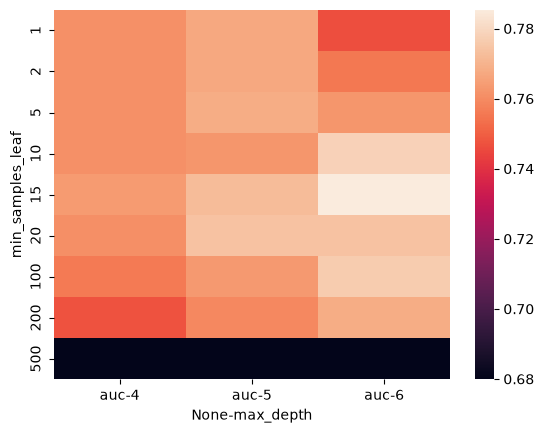

In [52]:
sns.heatmap(df_scores_pivot)

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

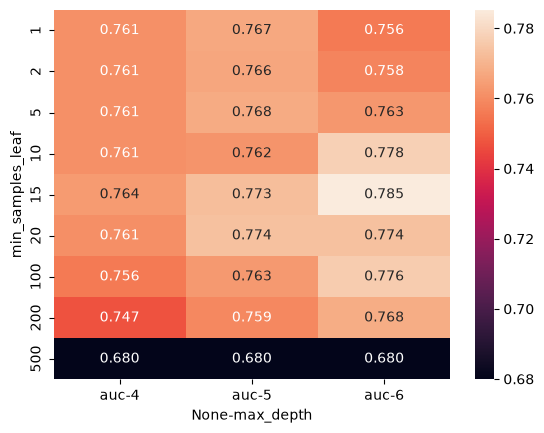

In [41]:
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

What about max search depth values? What about 7 or even 10? The way Alexey usually works is to firsth tune the `max_depth` parameter, and then tune the `min_samples_leaf` parameter. 

For this particular dataset it makes sense to try more values; but if the dataset is big, we cannot try every possible combination: We need to restrict our search space when we are trying to find the best parameters.

In this case it makes sense to try other values because the dataset is small.

In [44]:
scores = []

for d in [4, 5, 6, 7, 10, 15, 20, None]:
    for s in [1, 2, 5, 10, 15, 20, 100, 200, 500]:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, s, auc))

In [45]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores.head()

,max_depth,min_samples_leaf,auc
0,4.0,1,0.761283
1,4.0,2,0.761283
2,4.0,5,0.761283
3,4.0,10,0.761283
4,4.0,15,0.763726


In [46]:
df_scores.sort_values(by='auc', ascending=False).head()

,max_depth,min_samples_leaf,auc
40,10.0,15,0.791801
58,20.0,15,0.788256
67,NaN,15,0.786972
49,15.0,15,0.786022
22,6.0,15,0.784856


In [47]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'],
                values=['auc'])
df_scores_pivot

auc                                                    \
max_depth              NaN      4.0       5.0       6.0       7.0       10.0   
min_samples_leaf                                                               
1                 0.646927  0.761283  0.766496  0.746537  0.750784  0.695618   
2                 0.682855  0.761283  0.766496  0.765491  0.745035  0.712374   
5                 0.717750  0.761283  0.767755  0.762651  0.756827  0.728897   
10                0.762681  0.761283  0.762276  0.777521  0.762591  0.768473   
15                0.786972  0.763726  0.771806  0.784856  0.779625  0.791801   
20                0.784345  0.760910  0.774028  0.773337  0.779183  0.784012   
100               0.779725  0.755937  0.763384  0.776434  0.779583  0.779725   
200               0.768479  0.747260  0.759073  0.768267  0.768479  0.768479   
500               0.679842  0.679842  0.679842  0.679842  0.679842  0.679842   

                                      
max_depth             15.0      20.0  
min_samples_leaf                      
1                 0.656426  0.653248  
2                 0.685603  0.686079  
5                 0.714581  0.720009  
10                0.760841  0.761949  
15                0.786022  0.788256  
20                0.782882  0.783276  
100               0.779725  0.779474  
200               0.768479  0.768479  
500               0.679842  0.679842

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

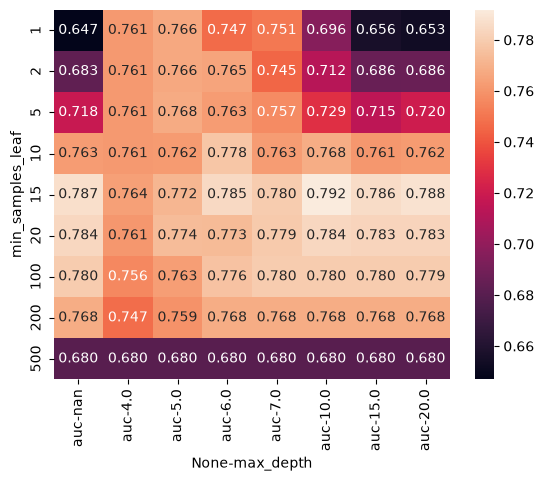

In [48]:
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

Even though we tuned with `None` as a parameter, it is not advisable to use it, because it is a situation where we do not hve control.

So to finish this section, we will tune with `HHHHHH` and `HHHHHH`.

In [49]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",15
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

## 6.6 Ensembles and Random Forest

*Random forest* is a way to put multiple decision trees together. 

$$
\frac{1}{n} \sum p_{i}
$$

Why random? Why not just forest? If we use the same application (set of features, parameters) to build multiple trees, those trees will be the same, and yield the same results.

In the random forest, the features for each of the applications are a little bit different. 

Features: assets, debt, price

DT#1: assets, debt

DT#2: assets, price

DT#3: debt, price

$$
\rightarrow \frac{1}{3}(p_{1} + p_{2} + p_{3})
$$

In [50]:
from sklearn.ensemble import RandomForestClassifier

In [51]:
rf = RandomForestClassifier(n_estimators=10, random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [52]:
y_pred = rf.predict_proba(X_val)[:, 1]

In [53]:
roc_auc_score(y_val, y_pred)

0.7744726453706618

In [54]:
rf.predict_proba(X_val[[0]])

array([[0.9, 0.1]])

If you train the model again, and then run predict_proba on X_val again, you will get different results.

In [55]:
rf.predict_proba(X_val[[0]])

array([[0.9, 0.1]])

In [56]:
# With the random_state fixed to 1

rf.predict_proba(X_val[[0]])

array([[0.9, 0.1]])

Let's see how the performance of our model changes when we increase the number of estimators.

In [57]:
scores = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators=n, random_state=1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append((n, auc))

In [58]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])

In [59]:
df_scores

,n_estimators,auc
0,10,0.774473
1,20,0.803532
2,30,0.815075
3,40,0.815686
4,50,0.817082
5,60,0.816458
6,70,0.817321
7,80,0.816307
8,90,0.816824
9,100,0.817599


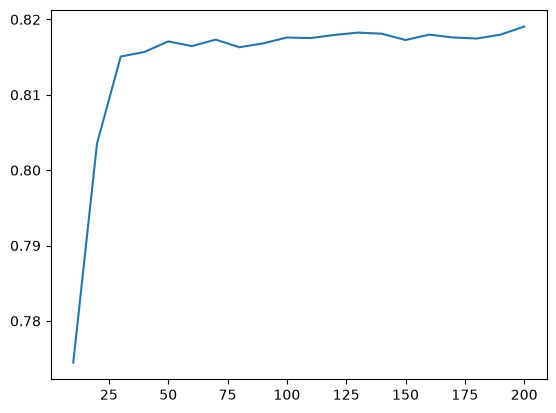

In [56]:
plt.plot(df_scores.n_estimators, df_scores.auc)

Tuning the max_steps parameter

In [60]:
scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, 
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)
    
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((d, n, auc))

In [61]:
columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores.head()

,max_depth,n_estimators,auc
0,5,10,0.787699
1,5,20,0.797731
2,5,30,0.800305
3,5,40,0.799708
4,5,50,0.799878


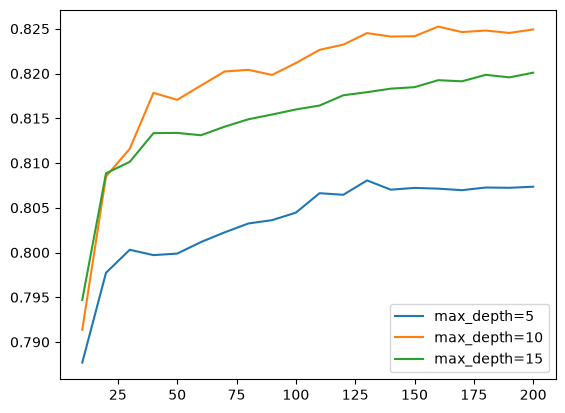

In [62]:
for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.auc, label='max_depth=%d' % d)

plt.legend()

Here we see that depth actually matters, and we need to set a good value for that. 10 is actually the best one. The difference between 10 and 15 is at least 1%, and the difference between 10 and five is around 2.5%.

Here we see that depth actually matters, and we need to set a good value for that. 10 is actually the best one.

In [63]:
max_depth = 10

In [64]:
scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, 
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1)
        rf.fit(X_train, y_train)
    
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((s, n, auc))

print("Finnished.")

Finnished.


In [65]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores.head()

,min_samples_leaf,n_estimators,auc
0,1,10,0.791365
1,1,20,0.808496
2,1,30,0.811584
3,1,40,0.817839
4,1,50,0.817058


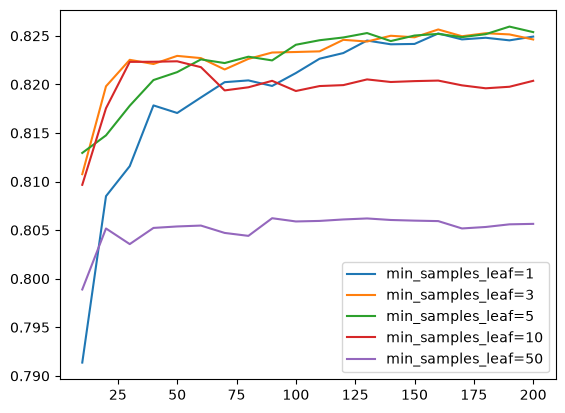

In [66]:
for s in [1, 3, 5, 10, 50]:
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.auc, 
             label='min_samples_leaf=%s' % s)

plt.legend()

In [67]:
colours = ['black', 'blue', 'orange', 'red', 'grey']
min_sample_leaf_values = [1, 3, 5, 10, 50]
# Need list() to display
list(zip(min_sample_leaf_values, colours))

[(1, 'black'), (3, 'blue'), (5, 'orange'), (10, 'red'), (50, 'grey')]

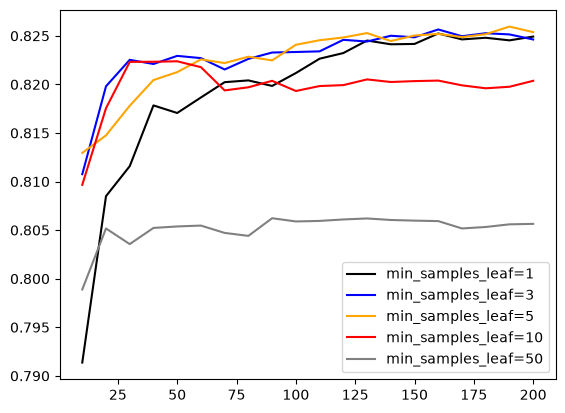

In [68]:
colours = ['black', 'blue', 'orange', 'red', 'grey']
min_sample_leaf_values = [1, 3, 5, 10, 50]

for s, col in zip(min_sample_leaf_values, colours):
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.auc, 
             color=col,
             label='min_samples_leaf=%s' % s)

plt.legend()

The grey one 50 is the worst one. 1, 3, 5 are at the top. Alexey chose `min_samples_leaf` value of 3 as the best value.

In [69]:
min_sample_leaf = 3

In [70]:
rf = RandomForestClassifier(n_estimators=100, 
                            max_depth=max_depth,
                            min_samples_leaf=min_sample_leaf,
                            random_state=1)
rf.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

This is our final random forest model which we will use when we compare all of the different models.

Other significant tunable parameters are:
- `max_features`: Specifies how many features each decision tree actually gets.
- `bootstrap`: Another method of randomisation, but on a raw level.
- `n_jobs`: The process of training decisions trees can be parallelised.

## 6.7 Gradient Boosting and XGBoost

Gradient boosting is a different way of combining multiple decision tree models into one ensemble. 

In boosting, we start with a data set; then we train the first model; the first model makes predictions, then we look at the predictions, and what are the errors that this model is making. Based on these errors we train another model. Then this second model makes predictions again. This model also makes some errors. Then we train a third model that corrects the predictions of the second model; we repeat this, and do this for many itterations. Finally we combine multiple predictions into the **final prediction**. The training of the series of models is sequential. 

In this sequence of models, if we replace each model with a tree, we get the idea of boosted trees.

NameError: name 'xgboost' is not defined